In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys 

from cherab.openadas import OpenADAS

In [2]:
sys.path.append("/home/tok4/fusion_modelling/perfil_emissao/doc_codes/Notebooks/Aparent Velocities (M1)/Emissivity Profile TCABR")

In [3]:
from Emissivity import read_file, get_emissivity

In [4]:
def matriz_pesos(y, r, method="zeros"):
    W = np.zeros((len(y), len(r)))
    
    if method == "zeros":
        dr = np.gradient(r)
        for i, yi in enumerate(y):
            mask = r > abs(yi)
            r_sub = r[mask]
            dr_sub = dr[mask]   
            
            termo = np.sqrt(r_sub**2 - yi**2)     
            pesos = 2.0 * r_sub * dr_sub / termo  
            pesos[termo < 2 * dr_sub] = 0.0      
            
            W[i, mask] = pesos
            
        return W  # Retorno FORA do loop for

    elif method == "cubic": # Alterado para elif
        dr = r[1] - r[0] if len(r) > 1 else np.gradient(r)
        for i, yi in enumerate(y):
            yi_abs = abs(yi)
            
            mask = r >= yi_abs
            r_sub = r[mask]
            
            if len(r_sub) == 0:
                continue
                
            r_ext = r_sub + dr
            
            termo_ext = np.sqrt(np.maximum(0.0, r_ext**2 - yi_abs**2))
            termo_int = np.sqrt(np.maximum(0.0, r_sub**2 - yi_abs**2))
            
            # Cálculo do comprimento do caminho analítico em cada anel
            pesos = 2.0 * (termo_ext - termo_int)
            
            W[i, mask] = pesos
            
        return W  # Retorno FORA do loop for

    else: 
        raise ValueError("Método inválido! Escolha entre 'zeros' ou 'cubic'.")

def direct_model(W, Eps, Vphi):
    S = W @ Eps
    U = W @ (Eps * Vphi)
    
    # Identifica onde S é zero
    zeros_mask = (S == 0)
    
    if np.any(zeros_mask):
        indices_zerados = np.where(zeros_mask)[0]
        print(f"AVISO: Divisão por zero identificada em S nas cordas/índices: {indices_zerados}")
    
    # Evita 0/0 definindo Vapp como 0 onde S == 0
    Vapp = np.zeros_like(U)
    valid_mask = ~zeros_mask
    Vapp[valid_mask] = U[valid_mask] / S[valid_mask]
    
    return Vapp

def Vphi_model(r, DeltaV, gama, a = 0.18):
    return gama * DeltaV * ((1-(r/a)**2)**(gama-1)) * (-2*(r/(a**2)))

def temp_model(r, T, gama,a = 0.18):
    DeltaT = T[0] - T[-1]
    return DeltaT * ((1-(r/a)**2)**gama) - T[-1]

def create_file(y,h,z):
    f = open("dados_simulados.csv", "w")
    f.write("impact_factor;height;lenght\n")
    for i, j, k in zip (y,h,z):       
        f.write(f"{i};{j};{k}\n")



In [5]:
adas = OpenADAS(permit_extrapolation = True)

In [6]:
## Reading the densities
df1 = pd.read_csv("../Emissivity Profile TCABR/data/dens_imp_carb.txt", sep = ";") # Densities in m^-3
df2 = pd.read_csv("../Emissivity Profile TCABR/data/dados_temp.txt", sep = ";") # Temperatures and ni
df3 = pd.read_csv("../Emissivity Profile TCABR/data/NeutralDemsity.txt", sep = "\s+")
df3.columns = ['raio','density_n']
for i in df3.columns:
    df3[i] = df3[i].astype(str).str.replace(",", ".")
    df3[i] = pd.to_numeric(df3[i],errors="coerce")

df_mesclado_novo = pd.merge_asof(df1,df2, on=df1.iloc[:,0], direction="nearest", tolerance=0.01)


df_mesclado =  pd.merge_asof(df_mesclado_novo,df3, left_on='raio[m]',right_on='raio', direction="nearest", tolerance=0.001)
df = df_mesclado.drop(columns = ["raio[m]", "raio_x",' c^+0[m^-3]', ' c^+1[m^-3]',
       ' c^+2[m^-3]', ' c^+3[m^-3]', ' c^+4[m^-3]',' TcTe[kev]',' Nc_tot[x10^19m^-1]'])
df = df.rename(columns = {"key_0": "raio[m]"})

df[' Ne[x10^19m^-1]'] = df[' Ne[x10^19m^-1]']*1e19
df[' Ni[x10^19m^-1]'] = df[' Ni[x10^19m^-1]']*1e19
df[' Te[kev]'] = df[' Te[kev]']*1e3
df[' Ti[kev]'] = df[' Ti[kev]']*1e3
df["raio[m]_normal"] = df["raio[m]"]/0.18

df.head()

,raio[m],Nz[m^-3],c^+5[m^-3],c^+6[m^-3],Te[kev],Ti[kev],Ne[x10^19m^-1],Ni[x10^19m^-1],raio_y,density_n,raio[m]_normal
0,0.000554,2.000000e+17,3.451860e+16,1.615500e+17,660.2,212.0,2.000000e+19,1.597400e+19,NaN,NaN,0.003078
1,0.001600,1.990000e+17,3.437890e+16,1.607060e+17,659.9,211.9,1.999000e+19,1.596600e+19,0.002,1.301640e+15,0.008889
2,0.002700,1.990000e+17,3.437890e+16,1.607060e+17,659.2,211.8,1.999000e+19,1.596600e+19,0.003,1.303290e+15,0.015000
3,0.003800,1.990000e+17,3.437820e+16,1.607030e+17,658.2,211.7,1.998000e+19,1.595800e+19,0.004,1.304950e+15,0.021111
4,0.004900,1.990000e+17,3.437820e+16,1.607030e+17,656.9,211.5,1.997000e+19,1.595400e+19,0.005,1.306630e+15,0.027222


In [7]:
minor_radius = 0.18 # meters
major_radius = 0.615 # meters

n = [100,400,800,1000,10000]
n_y = 16
gama = 4

#r = df["raio[m]"]
ion_c5_density = []
ion_c6_density = []
temp = []
r_list = []
for n in n:
    r = np.linspace(0, minor_radius, n)
    r_list.append(r)
    temp.append(np.interp(r, df["raio[m]"], df[" Te[kev]"]))
    ion_c5_density.append(np.interp(r, df["raio[m]"], df[" c^+5[m^-3]"]))
    ion_c6_density.append(np.interp(r, df["raio[m]"], df[" c^+6[m^-3]"]))
    

y = np.linspace(0, minor_radius, n_y)

In [8]:
T_profile = [temp_model(r_list[i],temp[i], gama) for i in range(0,len(r_list))]
w = [matriz_pesos(y,r_list[i],method = "zeros") for i in range(0,len(r_list))]
Vphi_profile = [Vphi_model(r_list[i],1,gama) for i in range(0,len(r_list))]


In [9]:
emissivity_per_n = []
for j in range(len(r_list)):
    emissivity = []
    for idx in range(len(r_list[j])):
        emissivity.append(get_emissivity(ne= 1e18, te = temp[j][idx], n_c5_eff = ion_c5_density[j][idx], n_c6_eff =ion_c6_density[j][idx]))
    emissivity_per_n.append(emissivity)

In [10]:
Vpp = [[] for j in range(len(w))]

for j in range(len(w)):
    vpp = direct_model(w[j],emissivity_per_n[j],Vphi_profile[j])
    Vpp[j].append(vpp)

AVISO: Divisão por zero identificada em S nas cordas/índices: [15]
AVISO: Divisão por zero identificada em S nas cordas/índices: [15]
AVISO: Divisão por zero identificada em S nas cordas/índices: [15]
AVISO: Divisão por zero identificada em S nas cordas/índices: [15]
AVISO: Divisão por zero identificada em S nas cordas/índices: [15]


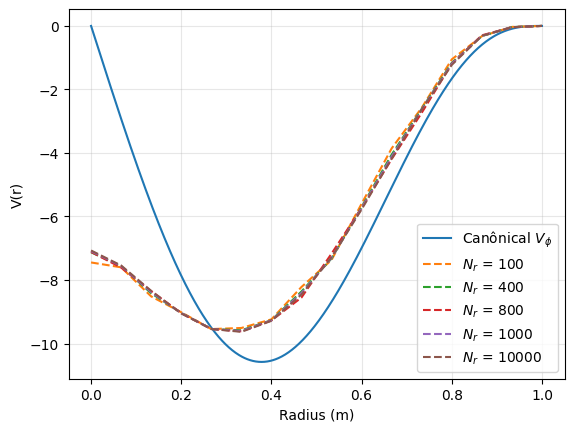

In [11]:
plt.plot(r_list[2]/r_list[2].max(), Vphi_profile[2], label = f"Canônical $V_{{\phi}}$")
for i in range(len(r_list)):
    plt.plot(y/y.max(), Vpp[i][0], ls = '--',label = f"$N_{{r}}$ = {len(r_list[i])}")
plt.xlabel("Radius (m)")
plt.ylabel("V(r)")
plt.legend()
plt.grid(True, which="both", alpha =0.3)
plt.savefig("Comparacao_Vphi_Vapp.png")
plt.show()

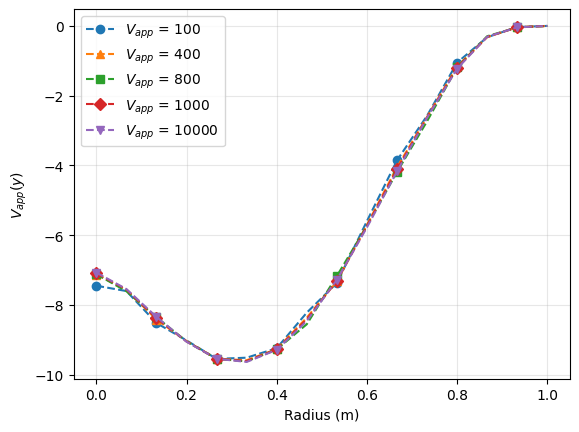

In [12]:
### Teste de convergência
markers = ['o', '^', 's', 'D', 'v', 'p', '*', 'X']
for i in range(len(r_list)):
    plt.plot(y/y.max(), Vpp[i][0], ls = '--', marker = markers[i], markevery  = 2,label = f"$V_{{app}}$ = {len(r_list[i])}")
plt.xlabel("Radius (m)")
plt.ylabel("$V_{{app}}(y)$")
plt.legend()
plt.grid(True, which="both", alpha =0.3)
plt.savefig("teste_convergência_curvas.png")
plt.show()

In [13]:
### Teste de convergência
Delta_V_list = []
for i in range(1,len(Vpp)):
    Delta_V = -1*abs(Vpp[i][0]-Vpp[i-1][0])/Vpp[i][0]
    Delta_V_list.append(Delta_V*100)

Delta_V_list

/tmp/ipykernel_10645/1934457073.py:4: RuntimeWarning: invalid value encountered in divide
  Delta_V = -1*abs(Vpp[i][0]-Vpp[i-1][0])/Vpp[i][0]


[array([ 4.51507905,  0.42043469,  1.1881002 ,  0.22419192,  0.01967   ,
         0.75578844,  0.28264927,  1.69750755,  0.63700806,  1.87439096,
         4.80569177,  1.37180431,  9.40470484,  1.68030329, 16.71810573,
                nan]),
 array([1.36062787e-01, 5.14621888e-01, 7.73530156e-01, 6.99169555e-02,
        1.42227435e-03, 3.49770600e-01, 7.92802211e-02, 2.22817714e+00,
        2.13966332e+00, 4.85143413e-01, 3.35839226e+00, 4.46899929e+00,
        2.16294597e+00, 7.93834089e+00, 1.15538065e+01,            nan]),
 array([3.53391815e-01, 6.70486003e-01, 3.53032363e-01, 1.80585658e-02,
        7.45202234e-03, 1.07944677e-01, 1.99584702e-02, 1.71465085e+00,
        1.84363047e+00, 1.19862200e-01, 1.97715658e+00, 4.26214878e+00,
        5.15450032e-01, 6.35865525e+00, 7.65516565e+00,            nan]),
 array([0.29506292, 0.1787689 , 0.48099711, 0.10586956, 0.00672338,
        0.26537319, 0.11387212, 0.60507746, 0.31679052, 0.66236772,
        1.50217371, 0.41932898, 2.6705799 

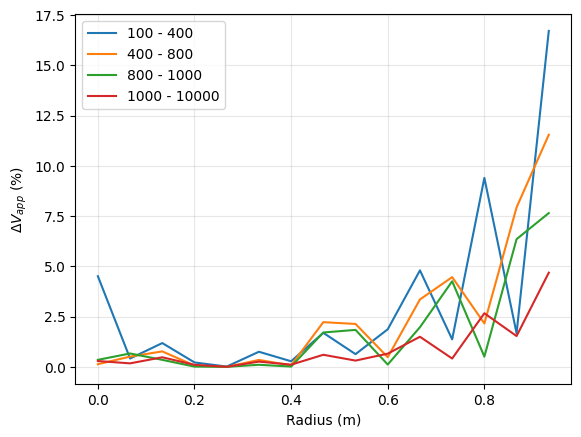

In [14]:
for i in range(0,len(Delta_V_list)):
    plt.plot(y/y.max(),Delta_V_list[i], label = f"{len(r_list[i])} - {len(r_list[i+1])}")
plt.xlabel("Radius (m)")
plt.ylabel("$\Delta V_{{app}}$ $(\%)$")
plt.legend()
plt.grid(True, which="both", alpha =0.3)
plt.savefig("teste_convergência.png")
plt.show()

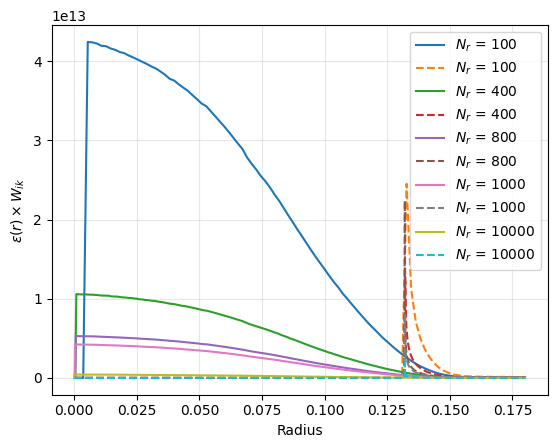

In [15]:
pesos_centro = [w[j][0, :] * emissivity_per_n[j] for j in range(0,len(r_list))]
pesos_borda = [w[j][11, :] * emissivity_per_n[j] for j in range(0,len(r_list))]

for j in range(len(r_list)):
    plt.plot(r_list[j], pesos_centro[j],label = f"$N_r$ = {len(r_list[j])}")
    plt.plot(r_list[j], pesos_borda[j],ls = '--', label = f"$N_r$ = {len(r_list[j])}")
#plt.plot(r_list[0]/r_list[0].max(), pesos_centro[0]/pesos_centro[0].max(),label = f"$N_r$ = {len(r_list[0])}")
#plt.plot(r_list[0]/r_list[0].max(), pesos_borda[0]/pesos_borda[0].max(),ls = '--', label = f"$N_r$ = {len(r_list[0])}")
plt.xlabel("Radius")
plt.ylabel(r"$\varepsilon (r) \times W_{{ik}}$")
plt.legend()
plt.grid(True, which = "both", alpha = 0.3)
plt.savefig("pesos.png")
plt.show()

In [16]:
w_cubic = [matriz_pesos(y,r_list[i],method = "cubic") for i in range(0,len(r_list))]

In [24]:
Vpp_cubic = [[] for j in range(len(w_cubic))]

for j in range(len(w)):
    vpp_cubic = direct_model(w_cubic[j],emissivity_per_n[j],Vphi_profile[j])
    Vpp_cubic[j].append(vpp_cubic)

In [25]:
Delta_V_list_cubic = []
for i in range(1,len(Vpp)):
    Delta_V_cubic = -1*abs(Vpp_cubic[i][0]-Vpp_cubic[i-1][0])/Vpp_cubic[i][0]
    Delta_V_list_cubic.append(Delta_V_cubic*100)

Delta_V_list_cubic

/tmp/ipykernel_10645/2258789014.py:3: RuntimeWarning: invalid value encountered in divide
  Delta_V_cubic = -1*abs(Vpp_cubic[i][0]-Vpp_cubic[i-1][0])/Vpp_cubic[i][0]


[array([ 0.83124468,  0.98190826,  1.37115713,  0.12994506,  0.0852695 ,
         0.09504152,  0.81190266,  2.11602238,  0.57976304,  2.51979135,
         1.56844137,  2.39685576, 10.56838256,  3.2679408 , 18.62117995,
                nan]),
 array([0.13780023, 0.04965115, 0.72075152, 0.06933884, 0.01844725,
        0.49739665, 0.25750641, 1.52704961, 0.88933564, 0.74764881,
        2.16844522, 2.39294762, 2.67937173, 2.49482981, 9.96072031,
               nan]),
 array([2.74947337e-02, 4.94273742e-01, 1.78544063e-01, 2.02675718e-02,
        1.77981953e-03, 4.76499458e-01, 6.70330334e-02, 7.90331485e-01,
        1.20122208e+00, 1.92591518e-01, 1.76780193e+00, 1.43271379e+00,
        6.62611988e-01, 4.04962379e+00, 3.99791645e+00,            nan]),
 array([9.87967833e-02, 5.90845603e-01, 6.72681315e-01, 1.40334520e-01,
        5.43228839e-03, 1.07082264e-02, 3.98437293e-01, 8.66210431e-01,
        4.61413405e-01, 1.12612542e+00, 2.34496662e-01, 1.28742548e+00,
        3.61429412e+00, 2.

In [26]:

Delta_V_list_cubic, Delta_V_list

([array([ 0.83124468,  0.98190826,  1.37115713,  0.12994506,  0.0852695 ,
          0.09504152,  0.81190266,  2.11602238,  0.57976304,  2.51979135,
          1.56844137,  2.39685576, 10.56838256,  3.2679408 , 18.62117995,
                 nan]),
  array([0.13780023, 0.04965115, 0.72075152, 0.06933884, 0.01844725,
         0.49739665, 0.25750641, 1.52704961, 0.88933564, 0.74764881,
         2.16844522, 2.39294762, 2.67937173, 2.49482981, 9.96072031,
                nan]),
  array([2.74947337e-02, 4.94273742e-01, 1.78544063e-01, 2.02675718e-02,
         1.77981953e-03, 4.76499458e-01, 6.70330334e-02, 7.90331485e-01,
         1.20122208e+00, 1.92591518e-01, 1.76780193e+00, 1.43271379e+00,
         6.62611988e-01, 4.04962379e+00, 3.99791645e+00,            nan]),
  array([9.87967833e-02, 5.90845603e-01, 6.72681315e-01, 1.40334520e-01,
         5.43228839e-03, 1.07082264e-02, 3.98437293e-01, 8.66210431e-01,
         4.61413405e-01, 1.12612542e+00, 2.34496662e-01, 1.28742548e+00,
         3.

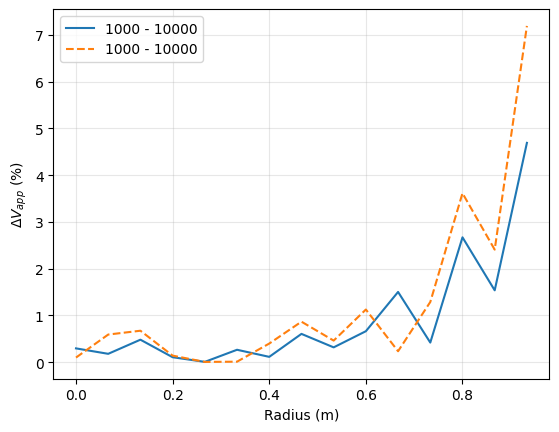

In [31]:
# for i in range(0,len(Delta_V_list)):
#     plt.plot(y/y.max(),Delta_V_list[i], label = f"{len(r_list[i])} - {len(r_list[i+1])}")
#     plt.plot(y/y.max(),Delta_V_list_cubic[i], ls = "--", label = f"{len(r_list[i])} - {len(r_list[i+1])}")
plt.plot(y/y.max(),Delta_V_list[3], label = f"{len(r_list[i])} - {len(r_list[i+1])}")
plt.plot(y/y.max(),Delta_V_list_cubic[3], ls = "--", label = f"{len(r_list[i])} - {len(r_list[i+1])}")
plt.xlabel("Radius (m)")
plt.ylabel("$\Delta V_{{app}}$ $(\%)$")
plt.legend()
plt.grid(True, which="both", alpha =0.3)
plt.savefig("teste_convergência.png")
plt.show()